# Required Imports

In [126]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cycler

from scipy import stats

# Disabilita usetex per evitare i RuntimeError di LaTeX mancante
plt.rcParams['text.usetex'] = False

# Wi-Fi Signals Processing

## Build CSI matrices from RAW data

In [127]:
def csv2csimatrix(file_path):
    # Legge il file ignorando le intestazioni
    df = pd.read_csv(file_path, header=None)

    # Gestisce il vecchio vs nuovo formato dei delimitatori
    if df.shape[1] == 1 and df.dtypes[0] == 'object':
        split_data = df[0].str.split(';', expand=True)
    else:
        split_data = df

    # Gestisce il vecchio vs nuovo numero di colonne
    if split_data.shape[1] == 128:
        # Nuovo formato: esattamente 128 colonne di dati CSI puri (nessun timestamp)
        raw_data = split_data.astype(float)
        timestamp_col = np.arange(len(split_data)) # Crea timestamp fittizi [0, 1, 2...]
    else:
        # Vecchio formato: >=130 colonne (le ultime due sono metadati/timestamp)
        raw_data = split_data.iloc[:, :-2].astype(float)
        timestamp_col = split_data.iloc[:, -2]

    # Combina parte reale e immaginaria nei numeri complessi
    complex_cols = [raw_data.iloc[:, i] + 1j * raw_data.iloc[:, i + 1] for i in range(0, raw_data.shape[1] - 1, 2)]

    # Crea la nuova matrice CSI
    csi_matrix = pd.DataFrame(complex_cols).transpose()

    # Le colonne fisse da droppare, basate sulla maschera OFDM a 64 subcarriers
    columns_to_drop = [0, 1, 2, 3, 4, 5, 32, 59, 60, 61, 62, 63]
    
    # Drop sicuro: elimina solo le colonne che esistono effettivamente, evitando crash
    csi_matrix.drop(columns=columns_to_drop, errors='ignore', inplace=True)
    
    # Per sicurezza contro anomalie, rinomina le colonne in ordine sequenziale da 0 a n
    csi_matrix.columns = range(csi_matrix.shape[1])

    # Salva il numero finale di sottoportanti valide (solitamente 52)
    n_subcarriers = csi_matrix.shape[1]

    # Aggiunge la colonna del timestamp per compatibilità
    csi_matrix['timestamp'] = timestamp_col

    return csi_matrix, n_subcarriers

In [128]:
def process_and_save_files(base_directory, output_folder):
    csi_collection = {}
    n_subcarriers = 0  
    
    output_path = os.path.join(output_folder, 'CSV', 'csi_matrices')
    os.makedirs(output_path, exist_ok=True)

    print(f"Scanning absolute path: {os.path.abspath(base_directory)}")
    
    # Traverse everything inside the folder
    for root, dirs, files in os.walk(base_directory):
        csv_files = [f for f in files if f.endswith('.csv')]
        
        if csv_files:
            subject = os.path.basename(root) # Grabs the folder name, e.g., "soggetto 1"
            print(f" -> Found {len(csv_files)} CSVs in folder: {subject}")
            
            for file_name in csv_files:
                file_path = os.path.join(root, file_name)
                
                try:
                    processed_csi, n_subcarriers = csv2csimatrix(file_path)

                    # Create composite ID, e.g., "soggetto1_saluto1"
                    file_id = f"{subject.replace(' ', '')}_{file_name.replace('.csv', '')}"
                    csi_collection[file_id] = processed_csi
                    
                    processed_csi.to_csv(os.path.join(output_path, f"{file_id}.csv"), index=False)
                except Exception as e:
                    print(f"   [ERROR] Failed on {file_name}: {e}")
                
    if not csi_collection:
        print(f"Warning: No CSV files were processed. Check if '{base_directory}' is truly empty to Python.")
    else:
        print(f"Success! Built and saved {len(csi_collection)} CSI matrices.")

    return csi_collection, n_subcarriers

# Go up one folder level to hit the root 'master-thesis' directory, then into 'acquisizioni'
input_directory = '../acquisizioni/'

# Folder to save the processed files
output_folder = './output/'
os.makedirs(output_folder, exist_ok=True)

# Process and save the files
csi_collection, n_subcarriers = process_and_save_files(input_directory, output_folder)

Scanning absolute path: /Users/antonio/Downloads/master-thesis/acquisizioni
 -> Found 10 CSVs in folder: soggetto 40
 -> Found 10 CSVs in folder: soggetto 22
 -> Found 10 CSVs in folder: soggetto 25
 -> Found 10 CSVs in folder: soggetto 13
 -> Found 10 CSVs in folder: soggetto 14
 -> Found 10 CSVs in folder: soggetto 41
 -> Found 10 CSVs in folder: soggetto 15
 -> Found 10 CSVs in folder: soggetto 12
 -> Found 10 CSVs in folder: soggetto 24
 -> Found 10 CSVs in folder: soggetto 23
 -> Found 10 CSVs in folder: soggetto 5
 -> Found 10 CSVs in folder: soggetto 2
 -> Found 10 CSVs in folder: soggetto 3
 -> Found 10 CSVs in folder: soggetto 4
 -> Found 10 CSVs in folder: soggetto 39
 -> Found 10 CSVs in folder: soggetto 30
 -> Found 10 CSVs in folder: soggetto 37
 -> Found 10 CSVs in folder: soggetto 36
 -> Found 10 CSVs in folder: soggetto 31
 -> Found 10 CSVs in folder: soggetto 38
 -> Found 10 CSVs in folder: soggetto 26
 -> Found 10 CSVs in folder: soggetto 19
 -> Found 10 CSVs in folde

## Compute Amplitude values from CSI matrices

### Raw Amplitude values

In [129]:
def compute_amplitude(csi_matrices):
    """Calcola l'ampiezza escludendo la colonna timestamp."""
    # Estrae solo le colonne dei dati CSI (tutte tranne l'ultima)
    data_cols = csi_matrices.drop(columns='timestamp', errors='ignore')
    
    # Calcola il modulo (valore assoluto) per i numeri complessi
    amplitude_data = data_cols.map(lambda csi: np.abs(csi) if isinstance(csi, complex) else csi)
    
    # Reinserisce il timestamp intatto
    if 'timestamp' in csi_matrices.columns:
        amplitude_data['timestamp'] = csi_matrices['timestamp']
        
    return amplitude_data

# Calcola le ampiezze per ogni ID
amplitudes = {ID: compute_amplitude(csi_matrices) for ID, csi_matrices in csi_collection.items()}

# Salva le ampiezze grezze
output_path = os.path.join(output_folder, 'CSV', 'raw_amplitudes')
os.makedirs(output_path, exist_ok=True)

for key, amp_df in amplitudes.items():
    new_file_name = f"{key}.csv"
    amp_df.to_csv(os.path.join(output_path, new_file_name), index=False)
    
print("Ampiezze raw calcolate e salvate con successo!")

Ampiezze raw calcolate e salvate con successo!


### Sanitize Amplitue values (Hampel filter)

In [130]:
def sanitize_amplitude_hampel(amplitude_values, window_size, xi):
    """Sanitize amplitude using the Hampel identifier."""
    # Salviamo i timestamp
    timestamps = amplitude_values['timestamp']
    amplitude_values = amplitude_values.drop(columns='timestamp')

    def hampel_filter(column):
        rolling_median = column.rolling(window=window_size, center=True).median()
        mad = lambda x: np.median(np.abs(x - np.median(x)))
        rolling_mad = column.rolling(window=window_size, center=True).apply(mad, raw=True)

        outliers = np.abs(column - rolling_median) > xi * rolling_mad
        column[outliers] = np.nan
        
        # Sintassi moderna per ffill e bfill
        column = column.ffill().bfill()
        return column

    # Applica il filtro colonna per colonna in modo sicuro
    sanitized_df = amplitude_values.apply(hampel_filter, axis=0)
    sanitized_df['timestamp'] = timestamps
    return sanitized_df

window_size = 50
xi = 3

hampel_amplitudes = {ID: sanitize_amplitude_hampel(df.copy(), window_size, xi) for ID, df in amplitudes.items()}

output_path = os.path.join(output_folder, 'CSV', 'sanitized_amplitudes', 'HF_amplitudes')
os.makedirs(output_path, exist_ok=True)

for key, df in hampel_amplitudes.items():
    df.to_csv(os.path.join(output_path, f"{key}.csv"), index=False)

print("Filtro Hampel completato!")

Filtro Hampel completato!


### Sanitize Amplitude values (Z-score)

In [131]:
def sanitize_amplitude_zscore(amplitude_values, threshold=3):
    """Sanitize amplitude using the Z-score method."""
    # Salviamo i timestamp per rimetterli alla fine
    timestamps = amplitude_values['timestamp']
    amplitude_values = amplitude_values.drop(columns='timestamp')
    
    # Calcola lo Z-score per ogni colonna in blocco (ignora i NaN esistenti)
    z_scores = np.abs(stats.zscore(amplitude_values, nan_policy='omit'))
    
    # Imposta come NaN tutti i valori dove lo Z-score supera la soglia
    sanitized_df = amplitude_values.mask(z_scores > threshold, np.nan)
    
    # Sintassi moderna per riempire i vuoti (avanti e poi indietro)
    sanitized_df = sanitized_df.ffill().bfill()
    
    # Reinserisci la colonna temporale
    sanitized_df['timestamp'] = timestamps
    return sanitized_df

# Esegue il filtro su tutti i dataframe
zscore_amplitudes = {ID: sanitize_amplitude_zscore(df.copy()) for ID, df in amplitudes.items()}

# Cartella di salvataggio
output_path = os.path.join(output_folder, 'CSV', 'sanitized_amplitudes', 'zscore_amplitudes')
os.makedirs(output_path, exist_ok=True)

# Salva i file
for key, df in zscore_amplitudes.items():
    df.to_csv(os.path.join(output_path, f"{key}.csv"), index=False)

print("Filtro Z-score completato senza errori!")

Filtro Z-score completato senza errori!


### Sanitize Amplitude values (Interquartile Range - IQR)

In [132]:
def sanitize_amplitude_iqr(amplitude_values):
    """Sanitize amplitude using the IQR method."""
    timestamps = amplitude_values['timestamp']
    amplitude_values = amplitude_values.drop(columns='timestamp')
    
    Q1 = amplitude_values.quantile(0.25)
    Q3 = amplitude_values.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Maschera vettoriale per valori fuori dai bound
    outlier_mask = (amplitude_values < lower_bound) | (amplitude_values > upper_bound)
    sanitized_df = amplitude_values.mask(outlier_mask, np.nan)
    
    # Riempimento in stile moderno
    sanitized_df = sanitized_df.ffill().bfill()
    
    sanitized_df['timestamp'] = timestamps
    return sanitized_df

# Calcolo IQR per tutte le matrici
iqr_amplitudes = {ID: sanitize_amplitude_iqr(df.copy()) for ID, df in amplitudes.items()}

# Salvataggio
output_path = os.path.join(output_folder, 'CSV', 'sanitized_amplitudes', 'iqr_amplitudes')
os.makedirs(output_path, exist_ok=True)

for key, df in iqr_amplitudes.items():
    df.to_csv(os.path.join(output_path, f"{key}.csv"), index=False)

print("Filtro IQR completato senza errori!")

Filtro IQR completato senza errori!


# Data visualization per ID

In [133]:
# Prende il primo ID disponibile nel dizionario invece di usare un nome inesistente
ID = list(amplitudes.keys())[0] 
print(f"Sto disegnando i grafici per il file: {ID}")

Sto disegnando i grafici per il file: soggetto40_tPose2


## Amplitude values

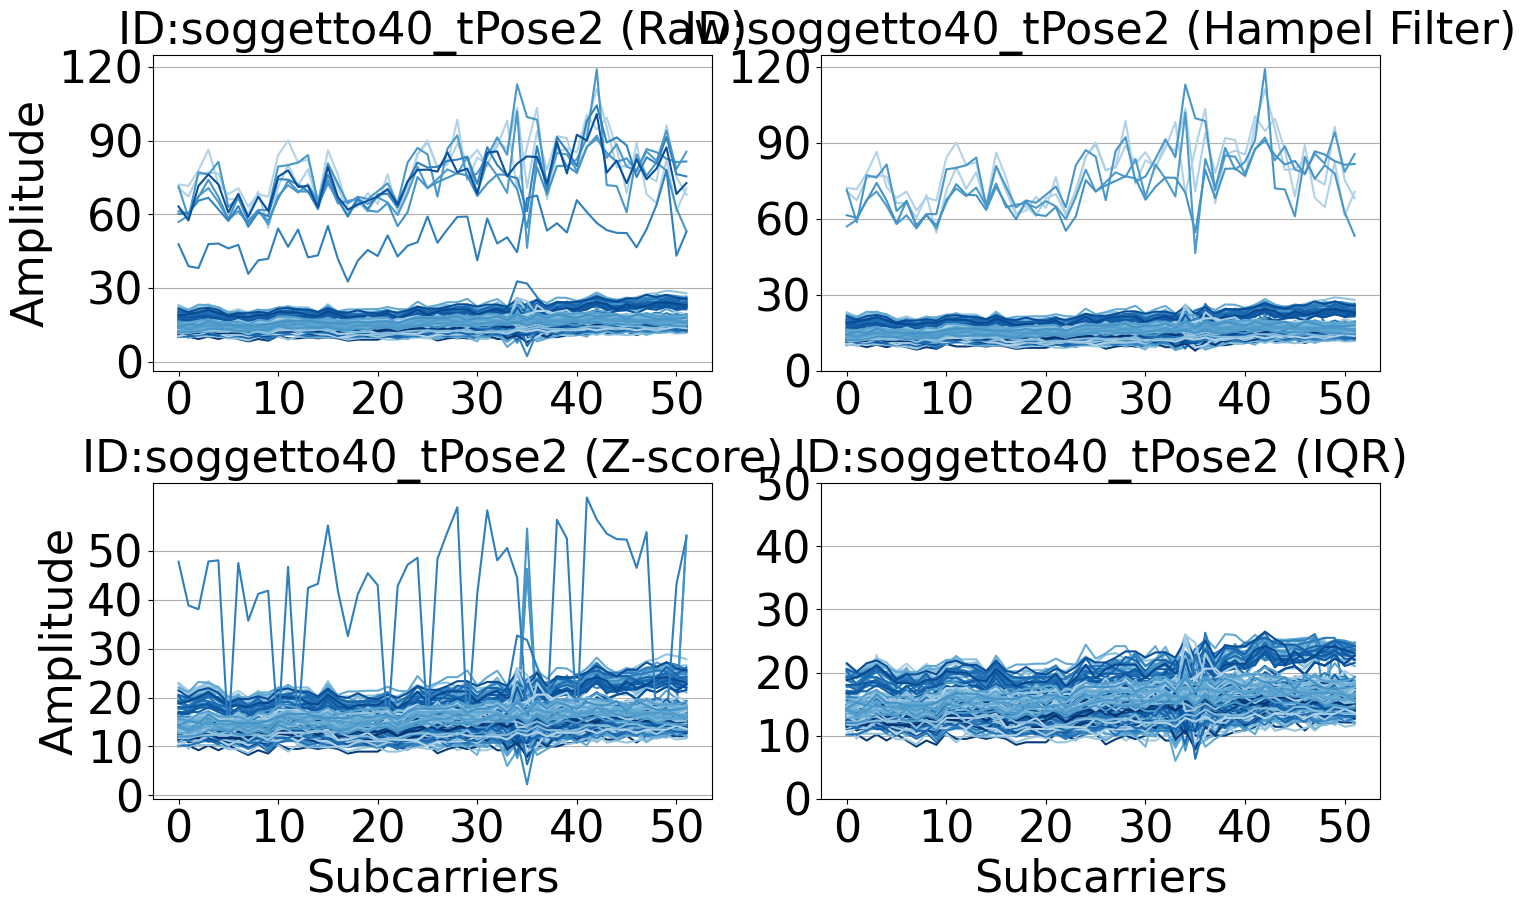

In [134]:
# Imposta il ciclo dei colori per il plot
color_cycle_a = cycler(color=plt.cm.Blues(np.linspace(0.3, 1, n_subcarriers)))

fig_magnitude, axes_magnitude = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes_mgntd = axes_magnitude.flatten()

for i in range(4):
    axes_mgntd[i].set_prop_cycle(color_cycle_a)

# Helper function per estrarre la serie sicura ed evitare Index Out Of Bounds
def get_safe_series(df, packet_idx):
    try:
        # Pulisce dai NaN prima del plot
        return df.drop(columns='timestamp').iloc[packet_idx, :].dropna().values
    except Exception:
        return []

# Plotting amplitude for the individual (Raw)
raw_df = amplitudes[ID]
for packet in range(len(raw_df)):
    series = get_safe_series(raw_df, packet)
    if len(series) > 0:
        axes_mgntd[0].plot(np.arange(len(series)), series, label=f'Subcarrier {packet}')

axes_mgntd[0].set_title(f'ID:{ID} (Raw)', fontsize=32)
axes_mgntd[0].set_ylabel('Amplitude', fontsize=32)
axes_mgntd[0].set_xticks(np.arange(0, n_subcarriers, 10))
axes_mgntd[0].set_yticks(np.arange(0, 150, 30))
axes_mgntd[0].tick_params(axis='both', which='major', labelsize=32)
axes_mgntd[0].grid(axis='y')

# Plotting amplitude (Hampel Filter)
hampel_df = hampel_amplitudes[ID]
for packet in range(len(hampel_df)):
    series = get_safe_series(hampel_df, packet)
    if len(series) > 0:
        axes_mgntd[1].plot(np.arange(len(series)), series, label=f'Subcarrier {packet}')

axes_mgntd[1].set_title(f'ID:{ID} (Hampel Filter)', fontsize=32)
axes_mgntd[1].set_xticks(np.arange(0, n_subcarriers, 10))
axes_mgntd[1].set_yticks(np.arange(0, 150, 30))
axes_mgntd[1].tick_params(axis='both', which='major', labelsize=32)
axes_mgntd[1].grid(axis='y')

# Plotting zscore amplitude (zscore)
zscore_df = zscore_amplitudes[ID]
for packet in range(len(zscore_df)):
    series = get_safe_series(zscore_df, packet)
    if len(series) > 0:
        axes_mgntd[2].plot(np.arange(len(series)), series, label=f'Subcarrier {packet}')

axes_mgntd[2].set_title(f'ID:{ID} (Z-score)', fontsize=32)
axes_mgntd[2].set_xlabel('Subcarriers', fontsize=32)
axes_mgntd[2].set_ylabel('Amplitude', fontsize=32)
axes_mgntd[2].set_xticks(np.arange(0, n_subcarriers, 10))
axes_mgntd[2].set_yticks(np.arange(0, 60, 10))
axes_mgntd[2].tick_params(axis='both', which='major', labelsize=32)
axes_mgntd[2].grid(axis='y')

# Plotting amplitude (IQR)
iqr_df = iqr_amplitudes[ID]
for packet in range(len(iqr_df)):
    series = get_safe_series(iqr_df, packet)
    if len(series) > 0:
        axes_mgntd[3].plot(np.arange(len(series)), series, label=f'Subcarrier {packet}')

axes_mgntd[3].set_title(f'ID:{ID} (IQR)', fontsize=32)
axes_mgntd[3].set_xlabel('Subcarriers', fontsize=32)
axes_mgntd[3].set_xticks(np.arange(0, n_subcarriers, 10))
axes_mgntd[3].set_yticks(np.arange(0, 60, 10))
axes_mgntd[3].tick_params(axis='both', which='major', labelsize=32)
axes_mgntd[3].grid(axis='y')

fig_magnitude.tight_layout(rect=[0, 0.03, 1, 0.95]) 
plt.show()

## Magnitude heatmaps

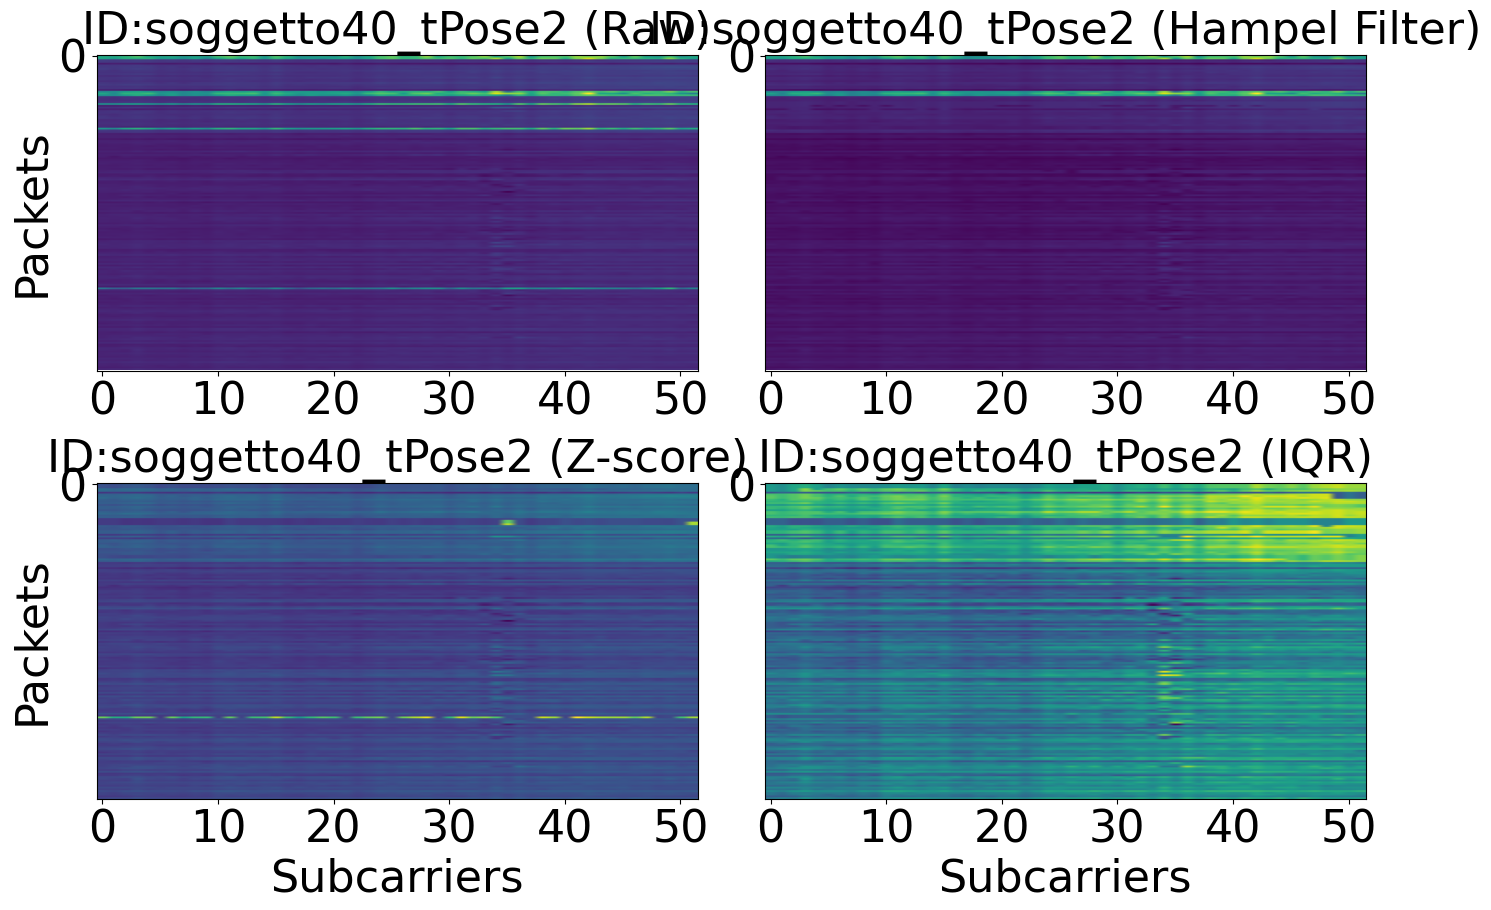

In [135]:
fig_magnitude, axes_magnitude = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes_mgntd = axes_magnitude.flatten()

# Extract matrices safely
mat_raw = amplitudes[ID].drop(columns='timestamp').apply(pd.to_numeric, errors='coerce').fillna(0).values
mat_hampel = hampel_amplitudes[ID].drop(columns='timestamp').apply(pd.to_numeric, errors='coerce').fillna(0).values
mat_zscore = zscore_amplitudes[ID].drop(columns='timestamp').apply(pd.to_numeric, errors='coerce').fillna(0).values
mat_iqr = iqr_amplitudes[ID].drop(columns='timestamp').apply(pd.to_numeric, errors='coerce').fillna(0).values

# Plot Raw
axes_mgntd[0].imshow(mat_raw, cmap='viridis', aspect='auto')
axes_mgntd[0].set_title(f'ID:{ID} (Raw)', fontsize=32)
axes_mgntd[0].set_ylabel('Packets', fontsize=32)
axes_mgntd[0].set_xticks(np.arange(0, mat_raw.shape[1], 10))
axes_mgntd[0].set_yticks(np.arange(0, mat_raw.shape[0], 200))
axes_mgntd[0].tick_params(axis='both', which='major', labelsize=32)

# Plot Hampel Filter
axes_mgntd[1].imshow(mat_hampel, cmap='viridis', aspect='auto')
axes_mgntd[1].set_title(f'ID:{ID} (Hampel Filter)', fontsize=32)
axes_mgntd[1].set_xticks(np.arange(0, mat_hampel.shape[1], 10))
axes_mgntd[1].set_yticks(np.arange(0, mat_hampel.shape[0], 200))
axes_mgntd[1].tick_params(axis='both', which='major', labelsize=32)

# Plot Z-score
axes_mgntd[2].imshow(mat_zscore, cmap='viridis', aspect='auto')
axes_mgntd[2].set_title(f'ID:{ID} (Z-score)', fontsize=32)
axes_mgntd[2].set_xlabel('Subcarriers', fontsize=32)
axes_mgntd[2].set_ylabel('Packets', fontsize=32)
axes_mgntd[2].set_xticks(np.arange(0, mat_zscore.shape[1], 10))
axes_mgntd[2].set_yticks(np.arange(0, mat_zscore.shape[0], 200))
axes_mgntd[2].tick_params(axis='both', which='major', labelsize=32)

# Plot IQR
axes_mgntd[3].imshow(mat_iqr, cmap='viridis', aspect='auto')
axes_mgntd[3].set_title(f'ID:{ID} (IQR)', fontsize=32)
axes_mgntd[3].set_xlabel('Subcarriers', fontsize=32)
axes_mgntd[3].set_xticks(np.arange(0, mat_iqr.shape[1], 10))
axes_mgntd[3].set_yticks(np.arange(0, mat_iqr.shape[0], 200))
axes_mgntd[3].tick_params(axis='both', which='major', labelsize=32)

fig_magnitude.tight_layout(rect=[0, 0.03, 1, 0.95]) 
plt.show()